# 3.3. Метод наименьших квадратов

Реализация: `lab3/lsq.py`. Нормальные системы для степеней 1 и 2, SSE, графики.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "lab3"

from lab3.dataio import read_vector
from lab3.lsq import least_squares_poly, sse, poly_eval, poly_string
import matplotlib.pyplot as plt

xs = read_vector(DATA / "3_3" / "x.txt")
ys = read_vector(DATA / "3_3" / "y.txt")
print("x =", xs)
print("y =", ys)


x = [-5.0, -3.0, -1.0, 1.0, 3.0, 5.0]
y = [2.9442, 2.8198, 2.3562, 0.7854, 0.32175, 0.1974]


## Многочлен 1-й степени

In [2]:

c1, A1, b1 = least_squares_poly(xs, ys, 1)
print("нормальная матрица A:")
for row in A1:
    print(row)
print("правая часть b =", b1)
print("F1(x) =", poly_string(c1))
sse1 = sse(xs, ys, c1)
print("SSE_1 =", sse1)


нормальная матрица A:
[6.0, 0.0]
[0.0, 70.0]
правая часть b = [9.424749999999998, -22.79895]
F1(x) = 1.570791667 - 0.3256992857*x
SSE_1 = 0.7006866120476188


## Многочлен 2-й степени

In [3]:

c2, A2, b2 = least_squares_poly(xs, ys, 2)
print("нормальная матрица A:")
for row in A2:
    print(row)
print("правая часть b =", b2)
print("F2(x) =", poly_string(c2))
sse2 = sse(xs, ys, c2)
print("SSE_2 =", sse2)


нормальная матрица A:
[6.0, 0.0, 70.0]
[0.0, 70.0, 0.0]
[70.0, 0.0, 1414.0]
правая часть b = [9.424749999999998, -22.79895, 109.95555000000002]
F2(x) = 1.570789062 - 0.3256992857*x + 2.232142858e-07*x^2
SSE_2 = 0.7006866120178571


## Графики

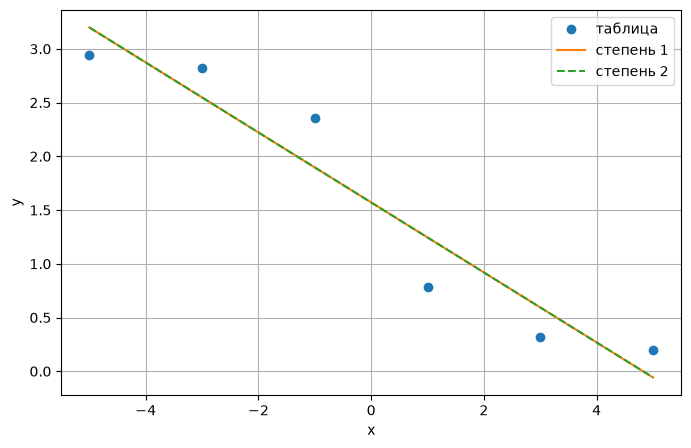

SSE_1 = 0.7006866120476188 SSE_2 = 0.7006866120178571


In [4]:

grid = [xs[0] + i * (xs[-1] - xs[0]) / 200 for i in range(201)]
y1 = [poly_eval(c1, t) for t in grid]
y2 = [poly_eval(c2, t) for t in grid]

plt.figure(figsize=(8, 5))
plt.plot(xs, ys, "o", label="таблица")
plt.plot(grid, y1, "-", label="степень 1")
plt.plot(grid, y2, "--", label="степень 2")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

print("SSE_1 =", sse1, "SSE_2 =", sse2)
